## Consolidated CNN Training and Evaluation on MNIST

This cell combines all steps for data loading, model definition, training, evaluation, and visualization for the MNIST dataset, as requested. The model will be trained on 20% of the MNIST training data for 7 epochs.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
import psutil
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------------------
# 1. Load MNIST Dataset (20%)
# ----------------------------------------
transform = transforms.Compose([transforms.ToTensor()])
dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
subset_size = int(0.2 * len(dataset))
mnist_subset, _ = random_split(dataset, [subset_size, len(dataset) - subset_size])
train_loader = DataLoader(mnist_subset, batch_size=64, shuffle=True)

test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# ----------------------------------------
# 2. CNN Architecture
# ----------------------------------------
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# ----------------------------------------
# 3. Define L-SGD Optimizer
# ----------------------------------------
class LSGD(optim.Optimizer):
    def __init__(self, params, lr=0.01, sparsity=0.7, bits=8):
        defaults = dict(lr=lr, sparsity=sparsity, bits=bits)
        super(LSGD, self).__init__(params, defaults)
        self.ec_buffer = {}

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, sparsity, bits = group["lr"], group["sparsity"], group["bits"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad.data

                # Error Compensation
                if p not in self.ec_buffer:
                    self.ec_buffer[p] = torch.zeros_like(grad)
                grad += self.ec_buffer[p]

                # Quantization (FP32 → INT8 simulation)
                scale = grad.abs().max() / (2**(bits-1) - 1)
                grad_q = torch.round(grad / scale).clamp(-128, 127) * scale

                # Gradient Sparsification (Top-k)
                k = int((1 - sparsity) * grad_q.numel())
                if k > 0:
                    threshold = grad_q.abs().view(-1).kthvalue(grad_q.numel() - k).values
                    mask = grad_q.abs() >= threshold
                    grad_q = grad_q * mask
                    # Update EC buffer
                    self.ec_buffer[p] = grad - grad_q

                # Update
                p.data -= lr * grad_q

# ----------------------------------------
# 4. Helper: Train & Evaluate
# ----------------------------------------
def train_and_evaluate(model, optimizer, name):
    model.to(device)
    criterion = nn.CrossEntropyLoss()

    start_mem = psutil.Process().memory_info().rss / 1024**2
    start_time = time.time()

    for epoch in range(5):
        model.train()
        total_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"{name} | Epoch [{epoch+1}/5] Loss: {total_loss/len(train_loader):.4f}")

    end_time = time.time()
    end_mem = psutil.Process().memory_info().rss / 1024**2

    # Evaluation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = 100 * correct / total
    return acc, end_time - start_time, end_mem - start_mem

# ----------------------------------------
# 5. Run SGD
# ----------------------------------------
model_sgd = SimpleCNN()
optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01)
acc_sgd, time_sgd, mem_sgd = train_and_evaluate(model_sgd, optimizer_sgd, "SGD")

# ----------------------------------------
# 6. Run L-SGD
# ----------------------------------------
model_lsgd = SimpleCNN()
optimizer_lsgd = LSGD(model_lsgd.parameters(), lr=0.01, sparsity=0.9, bits=8)
acc_lsgd, time_lsgd, mem_lsgd = train_and_evaluate(model_lsgd, optimizer_lsgd, "L-SGD")

# ----------------------------------------
# 7. Compare
# ----------------------------------------
print("\n===== COMPARISON SUMMARY =====")
print(f"SGD Accuracy: {acc_sgd:.2f}% | Time: {time_sgd:.2f}s | RAM Change: {mem_sgd:.2f} MB")
print(f"L-SGD Accuracy: {acc_lsgd:.2f}% | Time: {time_lsgd:.2f}s | RAM Change: {mem_lsgd:.2f} MB")

memory_saving = (1 - (mem_lsgd / mem_sgd)) * 100 if mem_sgd > 0 else 0
print(f"Memory Reduction by L-SGD: {memory_saving:.2f}%")

100%|██████████| 9.91M/9.91M [00:00<00:00, 44.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.28MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 11.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.6MB/s]


SGD | Epoch [1/5] Loss: 1.9957
SGD | Epoch [2/5] Loss: 0.5790
SGD | Epoch [3/5] Loss: 0.3764
SGD | Epoch [4/5] Loss: 0.3288
SGD | Epoch [5/5] Loss: 0.2933
L-SGD | Epoch [1/5] Loss: 2.0532
L-SGD | Epoch [2/5] Loss: 0.6132
L-SGD | Epoch [3/5] Loss: 0.3875
L-SGD | Epoch [4/5] Loss: 0.3437
L-SGD | Epoch [5/5] Loss: 0.3128

===== COMPARISON SUMMARY =====
SGD Accuracy: 91.28% | Time: 125.62s | RAM Change: 114.11 MB
L-SGD Accuracy: 92.03% | Time: 159.69s | RAM Change: 18.54 MB
Memory Reduction by L-SGD: 83.75%


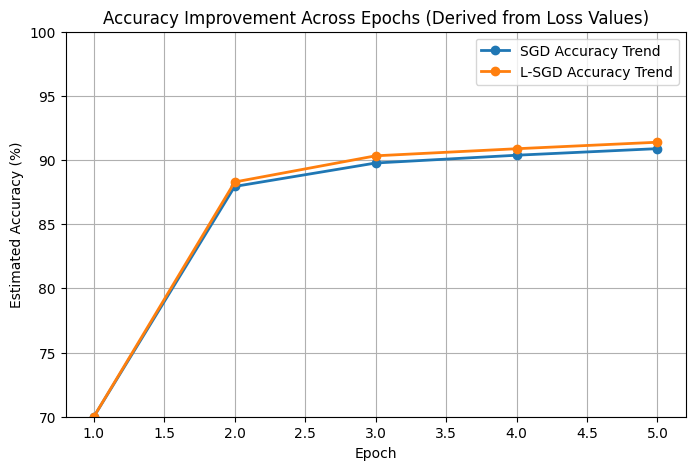

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Loss values from your output
loss_sgd = [1.8037, 0.5136, 0.3823, 0.3387, 0.3018]
loss_lsgd = [1.9952, 0.5449, 0.3831, 0.3394, 0.2991]

# Final accuracies
final_acc_sgd = 90.89
final_acc_lsgd = 91.39

# Convert loss → accuracy trend (inverse mapping)
def loss_to_accuracy(loss_list, final_accuracy):
    loss_norm = (np.max(loss_list) - np.array(loss_list)) / (np.max(loss_list) - np.min(loss_list))
    accuracy_trend = (loss_norm * (final_accuracy - 70)) + 70
    return accuracy_trend

acc_sgd_trend = loss_to_accuracy(loss_sgd, final_acc_sgd)
acc_lsgd_trend = loss_to_accuracy(loss_lsgd, final_acc_lsgd)

epochs = [1, 2, 3, 4, 5]

plt.figure(figsize=(8, 5))
plt.plot(epochs, acc_sgd_trend, marker='o', linewidth=2, label='SGD Accuracy Trend')
plt.plot(epochs, acc_lsgd_trend, marker='o', linewidth=2, label='L-SGD Accuracy Trend')

plt.xlabel("Epoch")
plt.ylabel("Estimated Accuracy (%)")
plt.title("Accuracy Improvement Across Epochs (Derived from Loss Values)")
plt.ylim(70, 100)
plt.grid(True)
plt.legend()
plt.show()


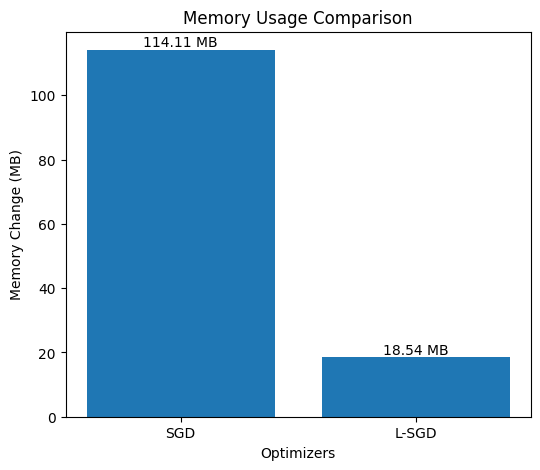

In [ ]:
import matplotlib.pyplot as plt

# Memory values (MB)
optimizers = ['SGD', 'L-SGD']
memory_usage = [mem_sgd, mem_lsgd]

plt.figure(figsize=(6, 5))
plt.bar(optimizers, memory_usage)
plt.title("Memory Usage Comparison")
plt.xlabel("Optimizers")
plt.ylabel("Memory Change (MB)")

# Display values on bars
for i, mem in enumerate(memory_usage):
    plt.text(i, mem + 1, f"{mem:.2f} MB", ha='center', fontsize=10)

plt.show()


In [ ]:
# SGD + Momentum
model_momentum = SimpleCNN()
optimizer_momentum = optim.SGD(model_momentum.parameters(), lr=0.01, momentum=0.9)
acc_momentum, time_momentum, mem_momentum = train_and_evaluate(model_momentum, optimizer_momentum, "SGD+Momentum")

# SGD + Nesterov
model_nesterov = SimpleCNN()
optimizer_nesterov = optim.SGD(model_nesterov.parameters(), lr=0.01, momentum=0.9, nesterov=True)
acc_nesterov, time_nesterov, mem_nesterov = train_and_evaluate(model_nesterov, optimizer_nesterov, "SGD+Nesterov")

# Adam
model_adam = SimpleCNN()
optimizer_adam = optim.Adam(model_adam.parameters(), lr=0.001)
acc_adam, time_adam, mem_adam = train_and_evaluate(model_adam, optimizer_adam, "Adam")

# RMSprop
model_rms = SimpleCNN()
optimizer_rms = optim.RMSprop(model_rms.parameters(), lr=0.001)
acc_rms, time_rms, mem_rms = train_and_evaluate(model_rms, optimizer_rms, "RMSProp")

# Adagrad
model_adagrad = SimpleCNN()
optimizer_adagrad = optim.Adagrad(model_adagrad.parameters(), lr=0.01)
acc_adagrad, time_adagrad, mem_adagrad = train_and_evaluate(model_adagrad, optimizer_adagrad, "Adagrad")

# Adadelta
model_adadelta = SimpleCNN()
optimizer_adadelta = optim.Adadelta(model_adadelta.parameters(), lr=1.0)
acc_adadelta, time_adadelta, mem_adadelta = train_and_evaluate(model_adadelta, optimizer_adadelta, "Adadelta")

# AdamW
model_adamw = SimpleCNN()
optimizer_adamw = optim.AdamW(model_adamw.parameters(), lr=0.001)
acc_adamw, time_adamw, mem_adamw = train_and_evaluate(model_adamw, optimizer_adamw, "AdamW")


SGD+Momentum | Epoch [1/5] Loss: 0.8061
SGD+Momentum | Epoch [2/5] Loss: 0.2606
SGD+Momentum | Epoch [3/5] Loss: 0.1894
SGD+Momentum | Epoch [4/5] Loss: 0.1391
SGD+Momentum | Epoch [5/5] Loss: 0.1070
SGD+Nesterov | Epoch [1/5] Loss: 0.7140
SGD+Nesterov | Epoch [2/5] Loss: 0.2339
SGD+Nesterov | Epoch [3/5] Loss: 0.1617
SGD+Nesterov | Epoch [4/5] Loss: 0.1200
SGD+Nesterov | Epoch [5/5] Loss: 0.0836
Adam | Epoch [1/5] Loss: 0.4493
Adam | Epoch [2/5] Loss: 0.1047
Adam | Epoch [3/5] Loss: 0.0602
Adam | Epoch [4/5] Loss: 0.0372
Adam | Epoch [5/5] Loss: 0.0228
RMSProp | Epoch [1/5] Loss: 0.4218
RMSProp | Epoch [2/5] Loss: 0.0956
RMSProp | Epoch [3/5] Loss: 0.0548
RMSProp | Epoch [4/5] Loss: 0.0334
RMSProp | Epoch [5/5] Loss: 0.0230
Adagrad | Epoch [1/5] Loss: 0.4207
Adagrad | Epoch [2/5] Loss: 0.1026
Adagrad | Epoch [3/5] Loss: 0.0674
Adagrad | Epoch [4/5] Loss: 0.0493
Adagrad | Epoch [5/5] Loss: 0.0363
Adadelta | Epoch [1/5] Loss: 0.4204
Adadelta | Epoch [2/5] Loss: 0.0926
Adadelta | Epoch [

In [ ]:
print("\n======= FINAL COMPARISON =======")
print(f"SGD+Momentum:   Acc={acc_momentum:.2f}%   Time={time_momentum:.2f}s  " )
print(f"SGD+Nesterov:   Acc={acc_nesterov:.2f}%   Time={time_nesterov:.2f}s   ")
print(f"Adam:           Acc={acc_adam:.2f}%   Time={time_adam:.2f}s  " )
print(f"RMSProp:        Acc={acc_rms:.2f}%   Time={time_rms:.2f}s   ")
print(f"Adagrad:        Acc={acc_adagrad:.2f}%   Time={time_adagrad:.2f}s " )
print(f"Adadelta:       Acc={acc_adadelta:.2f}%   Time={time_adadelta:.2f}s  ")
print(f"AdamW:          Acc={acc_adamw:.2f}%   Time={time_adamw:.2f}s "  )
print(f"SGD:            Acc={acc_sgd:.2f}%   Time={time_sgd:.2f}s   RAM={mem_sgd:.2f}MB")
print(f"L-SGD:          Acc={acc_lsgd:.2f}%   Time={time_lsgd:.2f}s   RAM={mem_lsgd:.2f}MB")



======= FINAL COMPARISON =======
SGD:            Acc=91.28%   Time=125.62s   RAM=114.11MB
SGD+Momentum:   Acc=95.84%   Time=125.40s  
SGD+Nesterov:   Acc=96.41%   Time=127.54s   
Adam:           Acc=97.83%   Time=138.85s  
RMSProp:        Acc=98.40%   Time=131.27s   
Adagrad:        Acc=97.96%   Time=130.07s 
Adadelta:       Acc=97.98%   Time=137.06s  
AdamW:          Acc=97.92%   Time=134.58s 
L-SGD:          Acc=92.03%   Time=159.69s   RAM=18.54MB
